# Upadłość przedsiębiorstw a status rodzinny

Model hazardu w czasie dyskretnym (panel firmo-lat). Notebook jest cienką warstwą
sterującą — cała logika mieszka w modułach `src/` (`data_load`, `pre_processing`,
`model`, `validation`, `inference`, `visualisation`).

**Oś pracy:** (1) predykcja upadłości XGBoost + test *skąd* pochodzi sygnał;
(2) inferencja o efekcie `family` — hierarchiczny logit hazardu, **regresja Firtha
z testem permutacyjnym** (odporność na 10 zdarzeń rodzinnych) i analiza warstwowa.

In [1]:
import sys
from pathlib import Path

# Korzen projektu niezaleznie od tego, skad uruchomiono notebook
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.append(str(PROJECT_ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score

from data_load import data_load
from pre_processing import (build_hazard_target, clean_panel, add_panel_features,
                            build_model_features, split_firms, winsorize_train_only, make_xy)
from model import train_model
from validation import find_threshold, bootstrap_ci, signal_source_test
import inference as inf
import visualisation as viz

sns.set_theme(style='whitegrid')

d:\studia\magisterka\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Wczytanie danych i definicja zmiennych

`RATIO_SET` przełącza zestaw wskaźników: `'X'` (surowe, ~59% braków) lub
`'new_X'` (oczyszczone przez dostawcę danych, ~45% braków — domyślne).

In [2]:
df = data_load(PROJECT_ROOT / 'data' / 'raw' / 'dane.dta')

RATIO_SET = 'X'  

id_cols      = ["TIN", "companyname", "NACECode", "year"]
family_cols  = ["family", "n_corp_group", "SHAREHOLDERS", "n_employees_", "TotalAssets"]
ratio_base   = [f"{RATIO_SET}{i}" for i in range(1, 16)]
ratio_cols   = ratio_base + ["roe", "profitmargin"]
event_date_cols = ["yearofbankruptcy", "yearofliquidation"]
struct_extra = ["ln_SHAREHOLDERS", "ln_businessgroup", "EBITDA", "fixedassets"]

cols_to_keep = (id_cols + ["dummy_upadlosc"] + family_cols + ratio_cols
                + ["Sales"] + event_date_cols + struct_extra)
df_model = df[cols_to_keep].copy()

print(f"[RATIO_SET={RATIO_SET}] wskazniki: {ratio_cols}")
print(df_model.isnull().mean().mul(100).sort_values(ascending=False).head(10).round(1))

[RATIO_SET=X] wskazniki: ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'roe', 'profitmargin']
yearofbankruptcy     99.9
dummy_upadlosc       99.9
yearofliquidation    94.6
n_employees_         81.5
X15                  68.3
X14                  67.4
X11                  66.5
X10                  65.5
X8                   65.2
X7                   63.0
dtype: float64


## 2. Konstrukcja zmiennej celu — target hazardu

`will_fail_next_year = 1`, gdy **następny** rok jest rokiem upadłości. Usuwamy rok
zdarzenia i lata późniejsze oraz stosujemy prawostronną cenzurę (funkcja
`build_hazard_target`). Poniżej kontrole zabezpieczające przed wyciekiem.

In [3]:
EVENT_YEAR_COLS = ['yearofbankruptcy']   # UPADLOSC (temat pracy); ['yearofliquidation'] = osobny model

df_model['dummy_upadlosc'] = df_model['dummy_upadlosc'].fillna(0)
df_model = df_model.sort_values(['TIN', 'year'])
df_model = build_hazard_target(df_model, EVENT_YEAR_COLS)

n_event = df_model.groupby('TIN')['event_year'].first().notna().sum()
print(f"Firm ze zdarzeniem: {n_event}")
print(f"Wierszy w panelu: {len(df_model)}; zdarzen (target=1): {int(df_model['will_fail_next_year'].sum())}")

chk = df_model.loc[df_model['will_fail_next_year'] == 1]
print(f"Kontrola - wszystkie target=1 maja year < event_year? {bool((chk['year'] < chk['event_year']).all())}")
print(f"Firm juz formalnie upadlych w roku predykcji (ma byc 0): {int((chk['dummy_upadlosc'] == 1).sum())}")

Firm ze zdarzeniem: 385
Wierszy w panelu: 2723508; zdarzen (target=1): 374
Kontrola - wszystkie target=1 maja year < event_year? True
Firm juz formalnie upadlych w roku predykcji (ma byc 0): 0


## 3. Diagnostyka braków (MNAR) i „firm-wydmuszek"

Braki we wskaźnikach nie są losowe: bankruci mają ich systematycznie *mniej*
(urwane sprawozdania to sygnał). Firmy o zerowych aktywach zachowujemy (flaga),
bo stanowią istotny udział upadłości.

In [4]:
mc = df_model[ratio_cols].isnull().sum(axis=1)
print(f"Wskaznikow ogolem: {len(ratio_cols)}")
braki_stat = df_model.assign(_mc=mc).groupby('will_fail_next_year')['_mc'].agg(['mean', 'median', 'count'])
braki_stat.index = ['Zdrowe (0)', 'Upadlosc (1)']
print("\nLiczba brakujacych wskaznikow wg klasy (test MNAR):")
print(braki_stat.round(2))

za = (df_model['TotalAssets'] <= 0)
print(f"\nFirmo-lata z aktywami <= 0: {int(za.sum())} ({za.mean()*100:.2f}%)")
print(f"  w tym bankruci (target=1): {int((za & (df_model['will_fail_next_year'] == 1)).sum())}")

Wskaznikow ogolem: 17

Liczba brakujacych wskaznikow wg klasy (test MNAR):
              mean  median    count
Zdrowe (0)    9.59    14.0  2723134
Upadlosc (1)  4.50     0.0      374

Firmo-lata z aktywami <= 0: 75322 (2.77%)
  w tym bankruci (target=1): 147


## 4. Czyszczenie panelu

Usuwamy jedynie skrajnie niekompletne wiersze (>12 z 17 braków). `clean_panel`
tworzy przy okazji cechy `zero_assets` i `missing_count`.

In [5]:
df_clean = clean_panel(df_model, ratio_cols, max_missing=12)
print(f"Wierszy po czyszczeniu: {len(df_clean)} (usunieto {len(df_model) - len(df_clean)} skrajnie pustych)")
print(f"Zdarzen zachowanych: {int(df_clean['will_fail_next_year'].sum())}")
print(f"Wierszy z zero_assets zachowanych: {int(df_clean['zero_assets'].sum())}")

Wierszy po czyszczeniu: 1317608 (usunieto 1405900 skrajnie pustych)
Zdarzen zachowanych: 372
Wierszy z zero_assets zachowanych: 71891


## 5. Cechy panelowe, podział firmowy i winsoryzacja

`add_panel_features` liczy zmiany rok-do-roku (`*_yoy`), `firm_age`, `n_years_obs`,
`nace_div`, `ebitda_margin`, `tangibility`. Podział na train/val/test odbywa się
**na poziomie firm** (TIN), a winsoryzacja 1% liczona jest **wyłącznie na treningu**.

In [6]:
df_clean = add_panel_features(df_clean, ratio_cols)
model_features, delta_cols = build_model_features(family_cols, ratio_cols)

df_clean = split_firms(df_clean, test_pct=0.20, val_pct=0.12, seed=42)
print("Firmy wg splitu:", df_clean.groupby('split')['TIN'].nunique().to_dict())

winsor_cols = (ratio_cols + delta_cols + ['n_corp_group', 'SHAREHOLDERS', 'n_employees_',
               'TotalAssets', 'Sales', 'ebitda_margin'])   # <— ZMIANA: bez 'tangibility'
df_clean = winsorize_train_only(df_clean, winsor_cols, clip=0.01)
print("Winsoryzacja (train-only) zakonczona.")

id_cols_seq = ['TIN', 'year', 'companyname', 'family', 'NACECode']
X_train, y_train, groups_train, ids_train = make_xy(df_clean, model_features, 'train', id_cols_seq)
X_val,   y_val,   groups_val,   ids_val   = make_xy(df_clean, model_features, 'val',   id_cols_seq)
X_test,  y_test,  groups_test,  ids_test  = make_xy(df_clean, model_features, 'test',  id_cols_seq)

print(f"\nTrain {X_train.shape}, Val {X_val.shape}, Test {X_test.shape}")
print(f"Pozytywy -> train {int(y_train.sum())}, val {int(y_val.sum())}, test {int(y_test.sum())}")
print("Overlap TIN train/test (ma byc 0):", len(set(groups_train) & set(groups_test)))

Firmy wg splitu: {'test': 52521, 'train': 178575, 'val': 31513}
Winsoryzacja (train-only) zakonczona.

Train (896718, 44), Val (157197, 44), Test (263693, 44)
Pozytywy -> train 256, val 46, test 70
Overlap TIN train/test (ma byc 0): 0


## 6. Eksploracyjna analiza danych (EDA)

Klasa 0 (zdrowe):    1317236 | Klasa 1 (upadlosc):      372 | niezbalansowanie ~ 1:3540


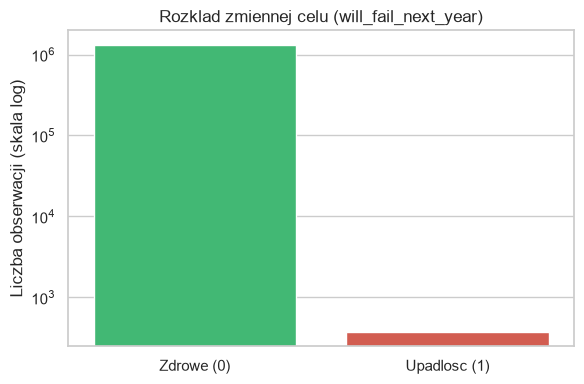

                 X1            X2            X3            X4            X5            X6            X7            X8            X9           X10          X11           X12           X13          X14          X15           roe  profitmargin
count  1.100401e+06  1.176159e+06  1.131467e+06  1.185892e+06  1.213625e+06  1.106015e+06  1.099477e+06  1.032520e+06  1.110694e+06  1.020548e+06  992724.0000  1.193032e+06  1.243202e+06  967961.0000  903189.0000  1.078554e+06  1.175074e+06
mean   1.784000e-01  3.100000e-02  5.756000e-01  2.480900e+00  9.730000e-02  4.851100e+00  1.742000e-01  2.245000e-01  3.693200e+00  2.429000e-01       0.7400  8.593000e-01  4.041000e-01       0.6591       2.8907  2.134100e+01  5.330200e+00
std    7.393000e-01  4.835000e-01  2.281900e+00  3.272500e+00  2.167000e-01  1.021540e+01  4.063000e-01  9.609000e-01  6.535800e+00  2.810000e-01       1.7997  3.312000e-01  4.922000e-01       0.7218       9.7020  7.026790e+01  2.235700e+01
min   -3.823500e+00 -2.692300e+00 -5

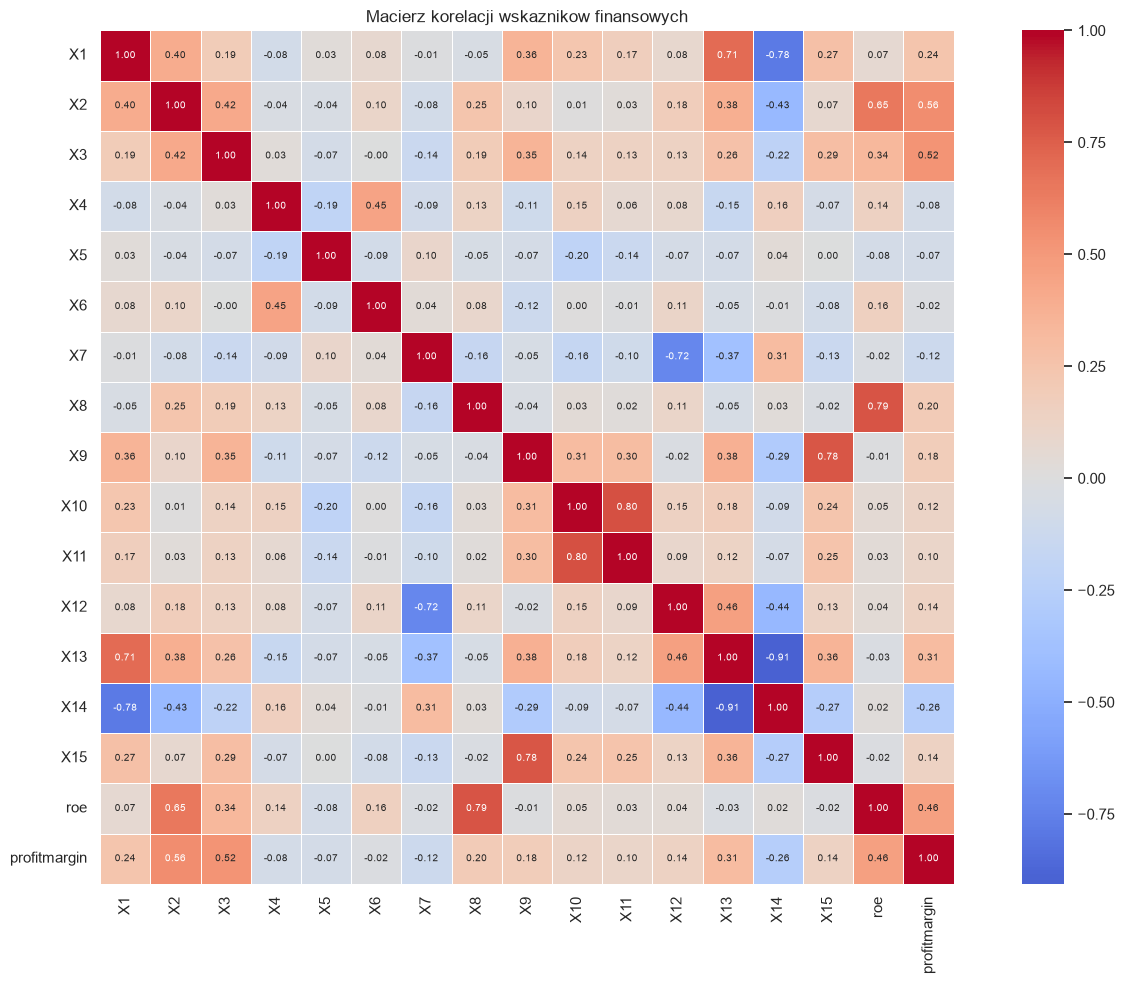

In [7]:
dist = df_clean['will_fail_next_year'].value_counts()
n0, n1 = int(dist.get(0.0, 0)), int(dist.get(1.0, 0))
print(f"Klasa 0 (zdrowe): {n0:>10} | Klasa 1 (upadlosc): {n1:>8} | niezbalansowanie ~ 1:{n0 // max(n1, 1)}")
viz.plot_target_distribution(df_clean)

print(df_clean[ratio_cols].describe().round(4).to_string())
viz.plot_corr_matrix(df_clean, ratio_cols)

## 7. Diagnostyka liczby zdarzeń w panelu

In [8]:
tot = int(y_train.sum() + y_val.sum() + y_test.sum())
print("Zdarzenia (target=1) na etapach:")
print(f"  df_model:            {int(df_model['will_fail_next_year'].sum())}")
print(f"  df_clean:            {int(df_clean['will_fail_next_year'].sum())}")
print(f"  train+val+test:      {tot}  (train {int(y_train.sum())}, val {int(y_val.sum())}, test {int(y_test.sum())})")

Zdarzenia (target=1) na etapach:
  df_model:            374
  df_clean:            372
  train+val+test:      372  (train 256, val 46, test 70)


## 8. Strojenie hiperparametrów XGBoost (Optuna, TPE)

`train_model` prowadzi optymalizację bayesowską z early stoppingiem na walidacji,
funkcją celu PR-AUC, a studium zapisuje w SQLite (można przerwać i wznowić).

In [9]:
STORAGE    = f"sqlite:///{(PROJECT_ROOT / 'models' / 'optuna_upadlosci.db').as_posix()}"
STUDY_NAME = f"xgb_bankruptcy_{RATIO_SET}_v1"
TARGET_TRIALS = 500

best_xgb, study = train_model(X_train, y_train, X_val, y_val,
                              n_trials=TARGET_TRIALS, storage=STORAGE, study_name=STUDY_NAME)

results = best_xgb.evals_result()
bi = getattr(best_xgb, 'best_iteration', None)
print(f"Drzew po early stopping: {bi + 1 if bi is not None else 'n/d'}")
best_xgb.save_model(str(PROJECT_ROOT / 'models' / 'xgboost_upadlosci.json'))
print("Model zapisany: models/xgboost_upadlosci.json")

[I 2026-08-03 19:48:22,786] Using an existing study with name 'xgb_bankruptcy_X_v1' instead of creating a new one.


Prob zakonczonych w bazie: 500. Do wykonania teraz: 0.
Target trials reached - zwieksz n_trials w configu, by dostroic wiecej.

Najlepszy PR-AUC (walidacja): 0.2082
Najlepsze parametry: {'learning_rate': 0.08024260671477959, 'max_depth': 5, 'min_child_weight': 80, 'subsample': 0.7137078590171494, 'colsample_bytree': 0.6295637364546984, 'gamma': 6.908347423207467, 'reg_alpha': 0.8227793354661962, 'reg_lambda': 9.843216230445345, 'max_delta_step': 1}
Drzew po early stopping: 149
Model zapisany: xgboost_upadlosci.json


## 9. Dobór progu (walidacja) i ocena na teście

Próg dobrany na walidacji dla `recall >= 0.90`, następnie zastosowany bez zmian
na teście. Score XGBoost przy `scale_pos_weight` **nie jest skalibrowanym
prawdopodobieństwem** — służy rankingowi.

Prog z walidacji dla recall>=90%: 0.2055

=== RAPORT KLASYFIKACJI (TEST) ===
              precision    recall  f1-score   support

         0.0     1.0000    0.9412    0.9697    263623
         1.0     0.0040    0.9000    0.0081        70

    accuracy                         0.9412    263693
   macro avg     0.5020    0.9206    0.4889    263693
weighted avg     0.9997    0.9412    0.9694    263693

ROC AUC: 0.9799   PR AUC: 0.0320


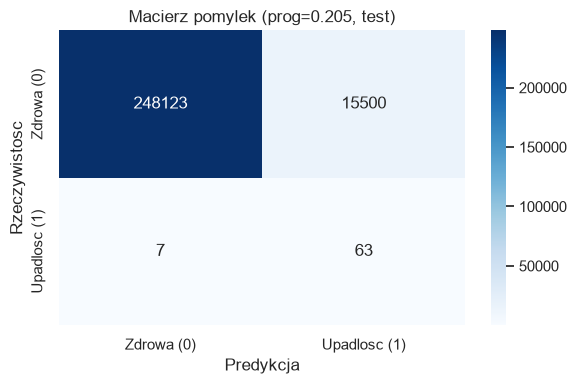

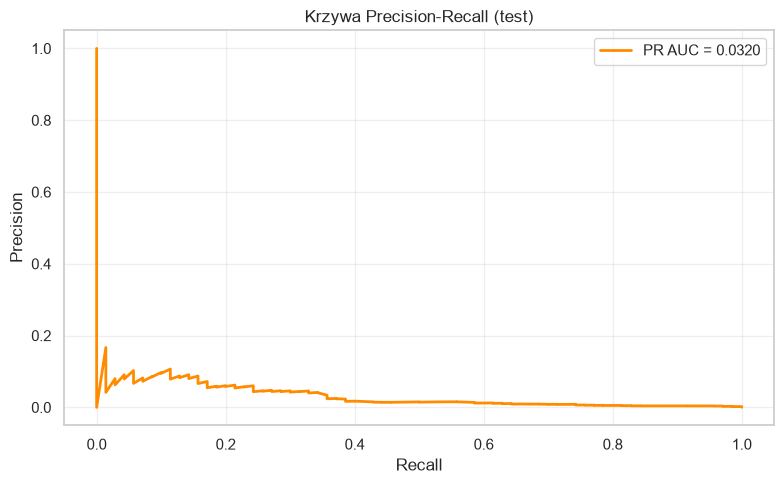

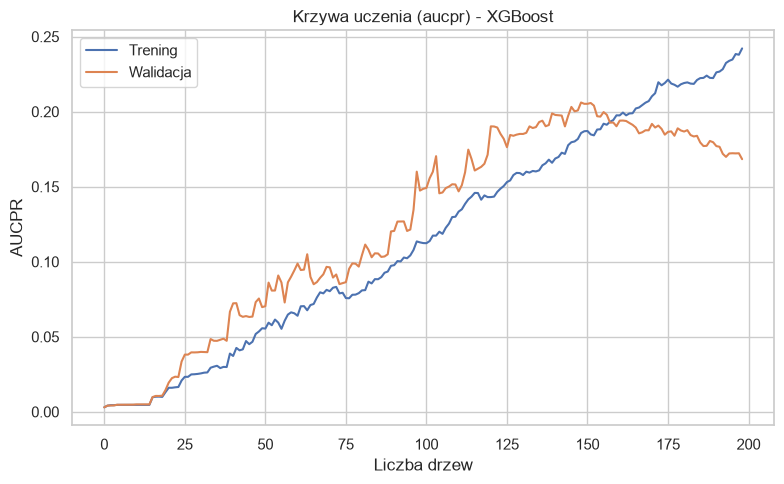

In [10]:
threshold = find_threshold(best_xgb, X_val, y_val, target_recall=0.90)

y_score_test = best_xgb.predict_proba(X_test)[:, 1]
y_pred_test  = (y_score_test > threshold).astype(int)

print("\n=== RAPORT KLASYFIKACJI (TEST) ===")
print(classification_report(y_test, y_pred_test, digits=4))

pr_auc = average_precision_score(y_test, y_score_test)
roc    = roc_auc_score(y_test, y_score_test)
print(f"ROC AUC: {roc:.4f}   PR AUC: {pr_auc:.4f}")

viz.plot_confusion(y_test, y_pred_test, threshold)
viz.plot_pr_curve(y_test, y_score_test, pr_auc)
viz.plot_learning_curve(results)

## 9b. Walidacja krzyzowa z podzialem na poziomie firm

W sekcjach 8 i 9 jeden zbior walidacyjny pelni trzy funkcje naraz: wczesne zatrzymanie, wybor
hiperparametrow i dobor progu decyzyjnego. Przy 46 zdarzeniach pozytywnych wybor najlepszego z 500
zestawow czesciowo dopasowuje sie do przypadkowych wlasciwosci tego zbioru, co widac po rozjezdzie
miedzy wynikiem walidacyjnym a testowym.

Walidacja krzyzowa usrednia wynik po kilku rozlacznych podzialach i daje oszacowanie wraz z
rozrzutem. Podzial odbywa sie na poziomie **firm** (grupa = TIN), ze stratyfikacja po zmiennej
celu - przy jednym zdarzeniu na 3541 firmo-lat zwykly `GroupKFold` dalby foldy o skrajnie roznej
liczbie zdarzen.

Zbior testowy nie uczestniczy w walidacji krzyzowej na zadnym etapie.

In [ ]:
# UWAGA: dlugo liczone. Kazda proba to N_SPLITS dopasowan XGBoost zamiast jednego,
# wiec koszt jest ok. 5x wyzszy niz w sekcji 8. Pruner medianowy przycina czesc prob.
# Studium zapisuje sie w osobnej bazie, wiec proces mozna przerwac i wznowic.
from cross_validation import train_model_cv
from validation import alarm_rate_from_oof, threshold_from_alarm_rate

N_TRIALS_CV = 100
N_SPLITS    = 5

# Walidacja krzyzowa obejmuje POLACZONY zbior uczacy i walidacyjny.
X_trval      = np.vstack([X_train, X_val])
y_trval      = np.concatenate([y_train, y_val])
groups_trval = np.concatenate([groups_train, groups_val])
print(f"Zbior do walidacji krzyzowej: {X_trval.shape}, zdarzen {int(y_trval.sum())}")
print(f"Overlap TIN z testem (ma byc 0): {len(set(groups_trval) & set(groups_test))}\n")

best_cv, study_cv, wynik_cv = train_model_cv(
    X_trval, y_trval, groups_trval,
    n_trials=N_TRIALS_CV,
    storage=f"sqlite:///{(PROJECT_ROOT / 'models' / 'optuna_upadlosci_cv.db').as_posix()}",
    study_name=f"xgb_bankruptcy_{RATIO_SET}_cv{N_SPLITS}_v1",
    n_splits=N_SPLITS, seed=42)

best_cv.save_model(str(PROJECT_ROOT / 'models' / 'xgboost_upadlosci_cv.json'))
print("Model zapisany: models/xgboost_upadlosci_cv.json")

In [ ]:
# Prog przenosimy przez ODSETEK ALARMOW, nie przez wartosc bezwzgledna: score'y
# modeli z poszczegolnych foldow i modelu koncowego maja rozne skale.
alarm_rate = alarm_rate_from_oof(y_trval, wynik_cv['oof'], target_recall=0.90)

y_score_cv = best_cv.predict_proba(X_test)[:, 1]
thr_cv     = threshold_from_alarm_rate(y_score_cv, alarm_rate)
y_pred_cv  = (y_score_cv > thr_cv).astype(int)

pr_auc_cv = average_precision_score(y_test, y_score_cv)
roc_cv    = roc_auc_score(y_test, y_score_cv)

print("\n=== POROWNANIE NA ZBIORZE TESTOWYM ===")
print(f"{'':30s} {'PR-AUC':>9} {'ROC-AUC':>9}")
print(f"{'Pojedynczy podzial (sekcja 9)':30s} {pr_auc:>9.4f} {roc:>9.4f}")
print(f"{'Walidacja krzyzowa':30s} {pr_auc_cv:>9.4f} {roc_cv:>9.4f}")

print("\n=== OSZACOWANIE ZE STROJENIA (czego spodziewalismy sie przed testem) ===")
print(f"Pojedynczy podzial: {study.best_value:.4f}   "
      f"(1 zbior, {int(y_val.sum())} zdarzen)")
print(f"Walidacja krzyzowa: {wynik_cv['prauc_mean']:.4f} +/- {wynik_cv['prauc_std']:.4f}   "
      f"({N_SPLITS} foldow, {int(y_trval.sum())} zdarzen)")
print(f"Rozjazd wzgledem testu: pojedynczy podzial {study.best_value - pr_auc_cv:+.4f}, "
      f"walidacja krzyzowa {wynik_cv['prauc_mean'] - pr_auc_cv:+.4f}")

ci_cv = bootstrap_ci(y_test, y_score_cv, thr_cv, groups=groups_test, B=2000)
print("\nPrzedzialy ufnosci (bootstrap klastrowany po firmie):")
for k, (lo, med, hi) in ci_cv.items():
    print(f"  {k:16s} {med:.4f}  [{lo:.4f}; {hi:.4f}]")

viz.plot_confusion(y_test, y_pred_cv, thr_cv)
viz.plot_pr_curve(y_test, y_score_cv, pr_auc_cv)

## 10. Bootstrapowe przedziały ufności — KLASTROWANE po firmie

**Poprawka metodologiczna:** przy panelu firmo-lat losujemy ze zwracaniem *całe
firmy* (klastry TIN), a nie pojedyncze wiersze. Losowanie wierszy zaniżałoby
szerokość CI, bo obserwacje tej samej firmy są skorelowane.

In [11]:
ci = bootstrap_ci(y_test, y_score_test, threshold, groups=groups_test, B=2000)
print(f"Bootstrap KLASTROWANY po TIN; pozytywow w tescie: {int(y_test.sum())}\n")
for k, (lo, md_, hi) in ci.items():
    print(f"  {k:15}: {md_:.4f}   95% CI [{lo:.4f}, {hi:.4f}]")

prevalence = y_test.mean()
print(f"\nPrevalencja (baseline PR-AUC): {prevalence:.6f}")
print(f"Lift PR-AUC nad baseline:      ~{pr_auc / prevalence:.0f}x")

Bootstrap KLASTROWANY po TIN; pozytywow w tescie: 70

  PR-AUC         : 0.0341   95% CI [0.0176, 0.0617]
  ROC-AUC        : 0.9800   95% CI [0.9732, 0.9857]
  Recall@prog    : 0.9026   95% CI [0.8235, 0.9672]
  Precision@prog : 0.0040   95% CI [0.0031, 0.0051]

Prevalencja (baseline PR-AUC): 0.000265
Lift PR-AUC nad baseline:      ~121x


## 11. Test źródła sygnału predykcyjnego

Ile mocy pochodzi z proxy „martwej firmy" (`zero_assets`, `missing_count`,
`firm_age`), a ile z samych wskaźników finansowych? Jeśli „tylko wskaźniki"
spada do poziomu losowego — klasyczny aparat altmanowski nie przewiduje upadłości.

In [12]:
scale_weight = (len(y_train) - y_train.sum()) / max(y_train.sum(), 1)
res = signal_source_test(X_train, y_train, X_val, y_val, X_test, y_test,
                         model_features, ratio_cols, scale_weight=scale_weight,
                         proxy_feats=('zero_assets','missing_count','firm_age',
                                      'SHAREHOLDERS','n_corp_group','n_employees_'))
print("PR-AUC (test) wg zestawu cech:")
print(f"  wszystkie cechy:              {res['wszystkie']:.4f}")
print(f"  BEZ proxy 'martwej firmy':    {res['bez_proxy']:.4f}  (spadek {res['wszystkie'] - res['bez_proxy']:+.4f})")
print(f"  TYLKO wskazniki finansowe:    {res['tylko_wskazniki']:.4f}")

PR-AUC (test) wg zestawu cech:
  wszystkie cechy:              0.0344
  BEZ proxy 'martwej firmy':    0.0419  (spadek -0.0075)
  TYLKO wskazniki finansowe:    0.0192


## 12. Analiza ryzyka na zbiorze testowym (out-of-sample) i lista zagrożonych firm

In [ ]:
analiza_df = ids_test.copy()
analiza_df['Ryzyko_Upadlosci_Score'] = y_score_test
analiza_df['Czy_Faktycznie_Upadla']  = y_test
if 'NACECode' in analiza_df.columns:
    analiza_df['NACE_sekcja'] = (analiza_df['NACECode'] // 100).apply(inf.nace_section)

alarmy = (analiza_df[analiza_df['Ryzyko_Upadlosci_Score'] > threshold]
          .sort_values('Ryzyko_Upadlosci_Score', ascending=False))
print(f"Firm zagrozonych (score > {threshold:.3f}) na tescie: {len(alarmy)}")
# Podglad bez danych identyfikujacych - pelna lista (z TIN i nazwa) trafia
# wylacznie do reports/, ktory jest wykluczony z repozytorium.
_id_cols = [c for c in ('TIN', 'companyname') if c in alarmy.columns]
print(alarmy.drop(columns=_id_cols).head(10).to_string())
alarmy.to_csv(PROJECT_ROOT / 'reports' / 'lista_zagrozonych_firm_xgboost.csv', index=False)
print("\nZapisano: reports/lista_zagrozonych_firm_xgboost.csv")

--- Srednie ryzyko: rodzinne vs nierodzinne (TEST) ---
           count      mean       std       min       25%       50%       75%  \
family                                                                         
0.0     200198.0  0.057635  0.198739  0.000015  0.000157  0.000284  0.000804   
1.0      63495.0  0.005760  0.029112  0.000016  0.000096  0.000152  0.000279   

             max  
family            
0.0     0.998753  
1.0     0.926054  


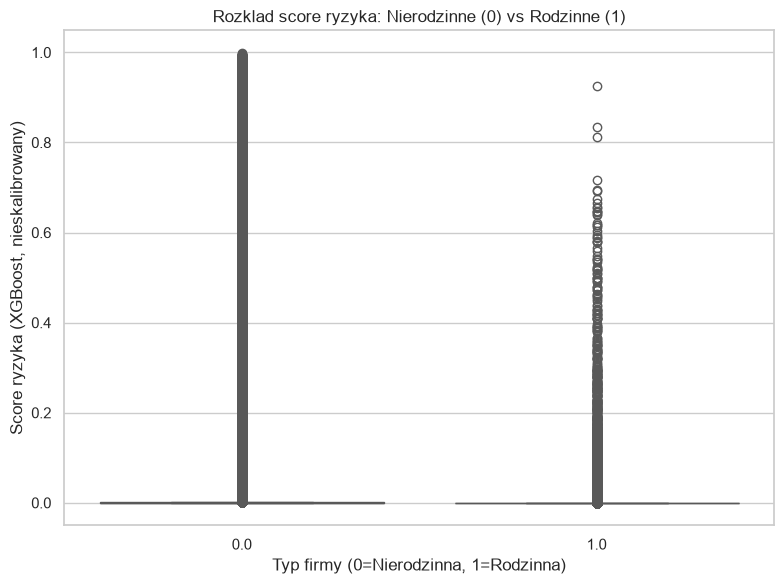

In [14]:
print("--- Srednie ryzyko: rodzinne vs nierodzinne (TEST) ---")
print(analiza_df.groupby('family')['Ryzyko_Upadlosci_Score'].describe())
viz.plot_risk_by_family(analiza_df)

# CZĘŚĆ INFERENCYJNA — czy firmy rodzinne upadają rzadziej i dlaczego?

## 13. Profil grup i surowa stopa upadłości (test χ²)

In [ ]:
rr = inf.raw_rate_by_family(df_clean)
print("--- Surowa stopa upadlosci wg family ---")
print(rr['table'])
print(f"\n>>> Rodzinne upadaja ~{rr['ratio']:.1f}x rzadziej; chi2={rr['chi2']:.1f}, p={rr['p']:.3g}")


## 14. Hierarchiczny logit hazardu (M1 → M3)

Pooled logit na panelu firmo-lat z błędami standardowymi **klastrowanymi po firmie**.
Stopniowe wprowadzanie kontroli pokazuje, czy efekt `family` przeżywa.

> **Uwaga:** to jedyny model inferencyjny w pracy. Wcześniejsza wersja włączała
> `profitmargin`/`roe` z `dropna()`, co przez 45–64% braków zawężało próbę do
> podzbioru MNAR i obciążało oszacowanie — dlatego została usunięta.

In [16]:
H = inf.hierarchical_hazard_logit(df_clean)
print(f"Obserwacji: {H['n']}, zdarzen: {H['n_events']}, w tym rodzinnych: {H['n_events_family']}\n")
print(H['table'][['family_OR', 'CI_lo', 'CI_hi', 'p', 'n_obs']].round(4).to_string())

d:\studia\magisterka\venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:2385: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-X))
d:\studia\magisterka\venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:2443: RuntimeWarning: divide by zero encountered in log
  return np.sum(np.log(self.cdf(q * linpred)))


Obserwacji: 1317604, zdarzen: 372, w tym rodzinnych: 10

                           family_OR   CI_lo   CI_hi    p    n_obs
model                                                             
M1: tylko family              0.0890  0.0475  0.1668  0.0  1317604
M2: + rozmiar/wiek/status     0.0820  0.0439  0.1534  0.0  1317604
M3: + sektor + rok            0.0293  0.0120  0.0717  0.0  1317604


## 15. Regresja Firtha (odporność na rzadkie zdarzenia)

**Kluczowa poprawka.** Przy ~10 zdarzeniach rodzinnych asymptotyczne p-value są
optymistyczne (King i Zeng, 2001). Regresja Firtha (penalizacja Jeffreysa) daje
skończone, obciążone-w-dół estymaty oraz **profilowy** przedział ufności PL.
Ta część liczy się w kilka minut na pełnym panelu (`n_perm=0` — bez permutacji).

In [17]:
d = df_clean.copy()
d['log_assets']       = np.log(d['TotalAssets'].clip(lower=1))
d['in_group']         = (d['n_corp_group'].fillna(0) > 0).astype(int)
d['sh_missing'] = d['SHAREHOLDERS'].isna().astype(int)
d['log_shareholders'] = np.log1p(d['SHAREHOLDERS'].fillna(d['SHAREHOLDERS'].median()))
CTRL = ['log_assets', 'firm_age', 'zero_assets']
FM = inf.firth_family_model(d, 'will_fail_next_year', controls=CTRL, n_perm=0)
print(FM['table'].to_string())
print(f"\n>>> family: OR = {FM['family_OR']:.3f}   "
      f"95% PL CI [{FM['family_CI'][0]:.3f}, {FM['family_CI'][1]:.3f}]   "
      f"p_wald = {FM['family_p_wald']:.3g}")
print(f"    n={FM['n']}, zdarzen={FM['n_events']}, rodzinnych={FM['n_events_family']}  (ostroznosc)")

Firth: dopasowanie na 1,317,604 wierszach, 372 zdarzen (rodzinnych: 10)...
  -> OR=0.086, PL CI [0.044, 0.151], p_wald=4.21e-15  (23.0s)
               coef       OR      se  p_wald
const       -8.7831   0.0002  0.3531  0.0000
family      -2.4540   0.0859  0.3127  0.0000
log_assets   0.0018   1.0018  0.0253  0.9441
firm_age     0.1366   1.1464  0.0245  0.0000
zero_assets  2.5173  12.3948  0.3657  0.0000

>>> family: OR = 0.086   95% PL CI [0.044, 0.151]   p_wald = 4.21e-15
    n=1317604, zdarzen=372, rodzinnych=10  (ostroznosc)


In [18]:
print(pd.crosstab(d['family'], d['sh_missing'], normalize='index'))

sh_missing         0         1
family                        
0.0         0.760138  0.239862
1.0         0.853646  0.146354


### 15b. (Opcjonalnie) Test permutacyjny — WOLNY

Każda z `n_perm` permutacji to osobne dopasowanie Firtha na **całym panelu**
(~1,5 mln wierszy), dlatego jest wolne: ~15–25 min dla `n_perm=1000` (warm-start,
z paskiem postępu i ETA drukowanym w trakcie). Status rodzinny tasowany jest
**na poziomie firmy** → uzyskane *p* jest niezależne od asymptotyki. Zacznij od
`n_perm=500` (~8 min); końcową wartość `p_perm` wpisz do pracy.

In [20]:
# UWAGA: dlugo liczone. Postep i ETA drukowane w trakcie. Zmniejsz n_perm w razie potrzeby.
FM = inf.firth_family_model(d, 'will_fail_next_year', controls=CTRL,
                            n_perm=500, perm_cap_iter=6)
print(f"\n>>> family: OR = {FM['family_OR']:.3f}   "
      f"95% PL CI [{FM['family_CI'][0]:.3f}, {FM['family_CI'][1]:.3f}]")
print(f"    p (Wald) = {FM['family_p_wald']:.3g}   |   "
      f"p (permutacyjny, klastrowany po firmie) = {FM['family_p_perm']:.4f}")
print(f"    n={FM['n']}, zdarzen={FM['n_events']}, rodzinnych={FM['n_events_family']}")

Firth: dopasowanie na 1,317,604 wierszach, 372 zdarzen (rodzinnych: 10)...
  -> OR=0.086, PL CI [0.044, 0.151], p_wald=4.21e-15  (22.9s)
  permutacje 50/500  (elapsed 0.8 min, ETA 6.9 min)
  permutacje 100/500  (elapsed 1.5 min, ETA 6.1 min)
  permutacje 150/500  (elapsed 2.3 min, ETA 5.3 min)
  permutacje 200/500  (elapsed 3.1 min, ETA 4.6 min)
  permutacje 250/500  (elapsed 3.8 min, ETA 3.8 min)
  permutacje 300/500  (elapsed 4.6 min, ETA 3.1 min)
  permutacje 350/500  (elapsed 5.4 min, ETA 2.3 min)
  permutacje 400/500  (elapsed 6.1 min, ETA 1.5 min)
  permutacje 450/500  (elapsed 6.9 min, ETA 0.8 min)
  permutacje 500/500  (elapsed 7.6 min, ETA 0.0 min)
  -> p_perm=0.0020  (7.6 min)

>>> family: OR = 0.086   95% PL CI [0.044, 0.151]
    p (Wald) = 4.21e-15   |   p (permutacyjny, klastrowany po firmie) = 0.0020
    n=1317604, zdarzen=372, rodzinnych=10


## 16. Czy to efekt kompozycji? Stopa upadłości w warstwach

Jeśli rodzinne mają niższą stopę w *każdej* warstwie wielkości i sektora, przewaga
nie jest artefaktem kompozycji próby.

In [ ]:
print("--- Stopa upadlosci (%) wg wielkosci (kwartyle aktywow) ---")
print(inf.stratified_rates(df_clean, 'TotalAssets', n_quantiles=4).to_string())


## 17. Wizualizacja: stopa upadłości wg wielkości i typu firmy

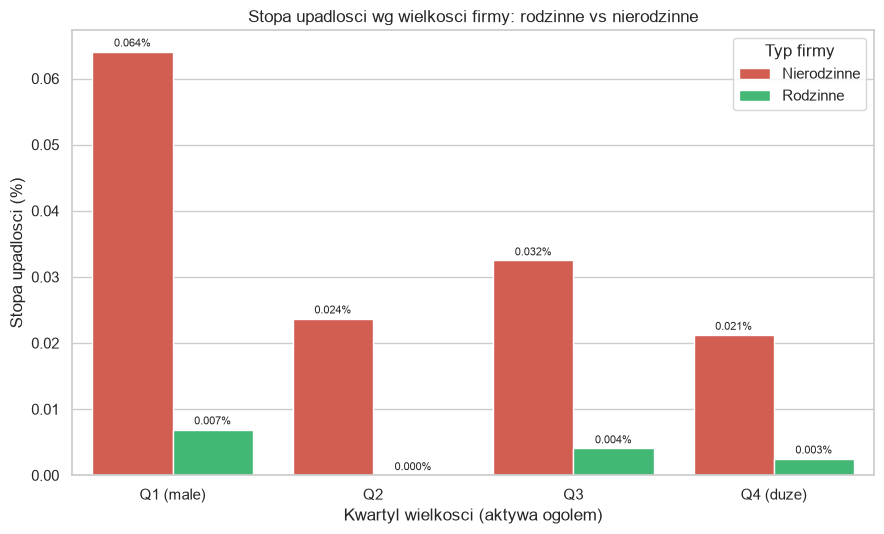

In [23]:
viz.plot_failure_rate_by_size(df_clean)

## 18. Interpretacja modelu — wartości SHAP

Inicjalizacja SHAP TreeExplainer...


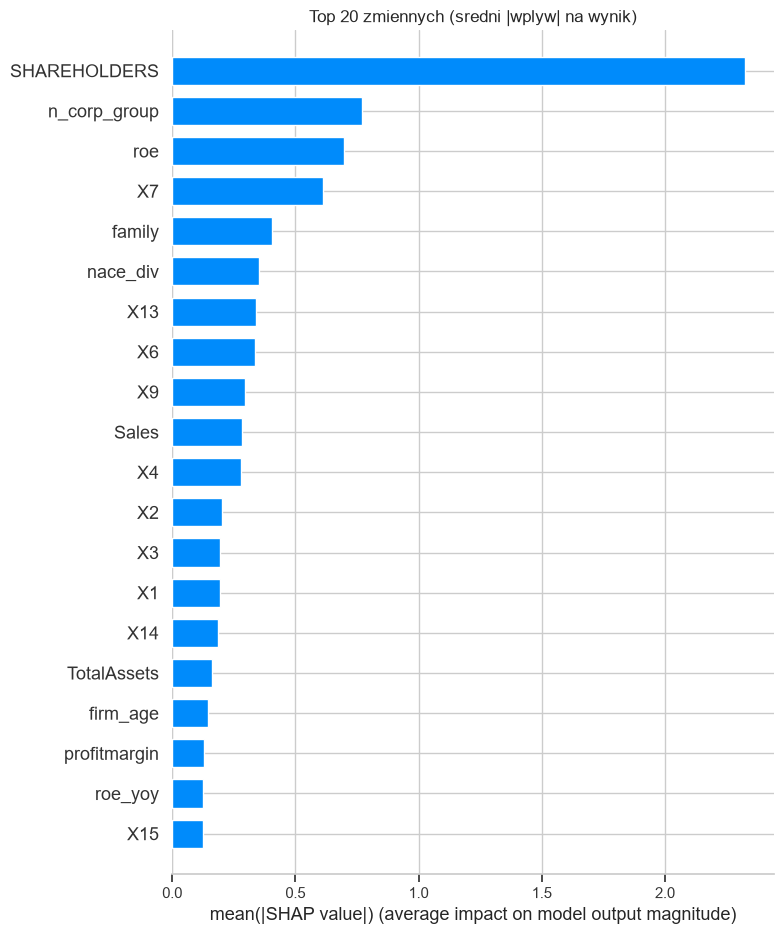

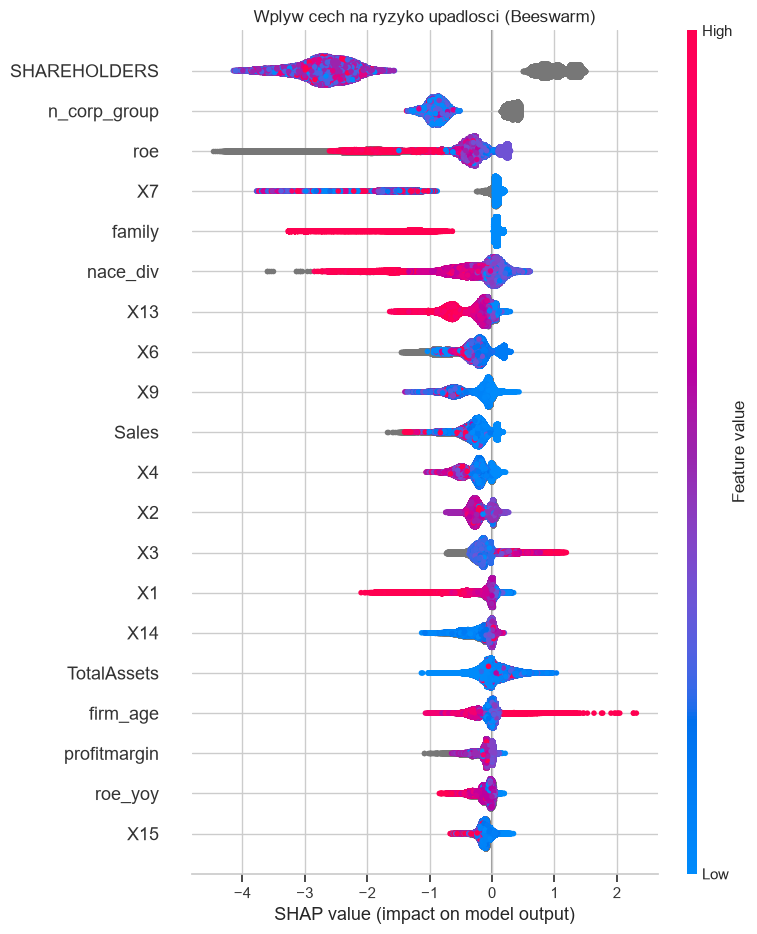

In [24]:
print("Inicjalizacja SHAP TreeExplainer...")
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer(X_test)
feat_names = list(model_features)

plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test, feature_names=feat_names, plot_type="bar",
                  max_display=20, show=False)
plt.title("Top 20 zmiennych (sredni |wplyw| na wynik)")
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test, feature_names=feat_names, max_display=20, show=False)
plt.title("Wplyw cech na ryzyko upadlosci (Beeswarm)")
plt.tight_layout(); plt.show()

Waterfall dla firmy idx=6447 (prawdziwa klasa: 1.0)


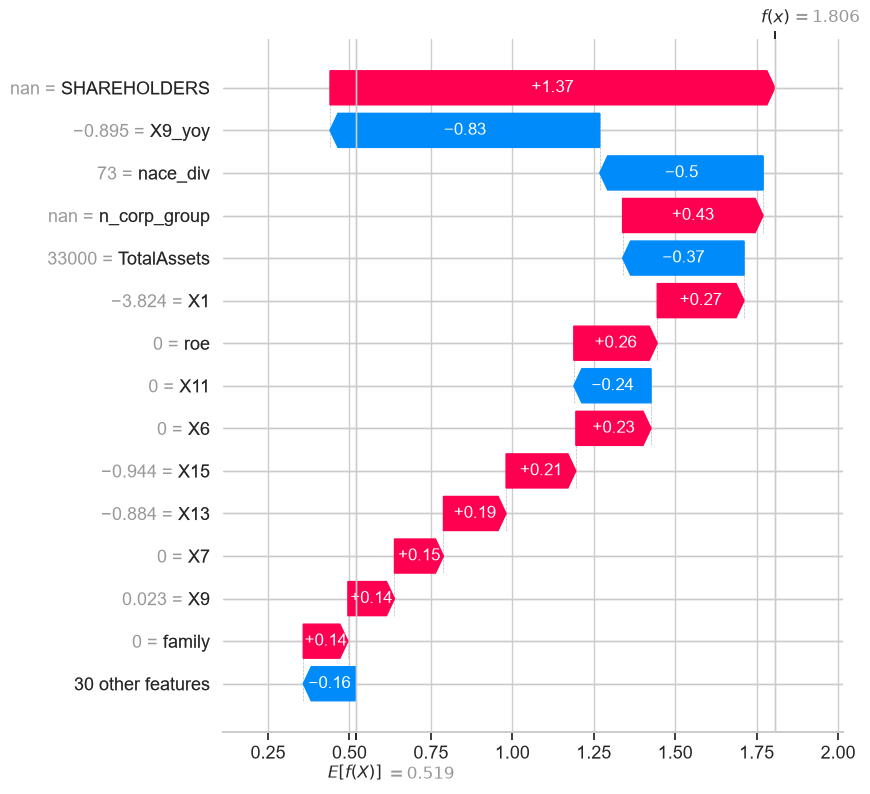

In [25]:
idx_to_explain = int(np.where(y_test == 1)[0][0]) if (y_test == 1).any() else 0
print(f"Waterfall dla firmy idx={idx_to_explain} (prawdziwa klasa: {y_test[idx_to_explain]})")

exp = shap.Explanation(
    values=shap_values.values[idx_to_explain],
    base_values=explainer.expected_value,
    data=X_test[idx_to_explain],
    feature_names=list(model_features),
)
shap.plots.waterfall(exp, max_display=15)